# Two-link robot arm: simulation sandbox

This notebook simulates the planar two-link arm of `envs/robot_arm.py` and visualises its trajectories. The arm is the test system for the dual controllers. The controllers know the geometry, the rotor inertia and the noise statistics, but they only hold a Gaussian prior on the payload mass $m_p$ and the joint damping $d_1, d_2$. They therefore have to learn these parameters while they move.

The arm moves in the horizontal plane according to

$$M(q;\theta)\,\ddot q + c(q,\dot q;\theta) + D(\theta)\,\dot q = u \, ,$$

with joint angles $q = (q_1, q_2)$, motor torques $u$, mass matrix $M$, Coriolis and centrifugal torques $c$, and damping $D = \mathrm{diag}(d_1, d_2)$. Sampled at $\Delta t = 0.05$ s, the arm takes the form of the paper's system class,

$$x_{k+1} = f(x_k, u_k; \theta) + w_k \, , \qquad y_k = g(x_k) + v_k \, ,$$

with state $x = (q_1, q_2, \dot q_1, \dot q_2)$, $f$ one RK4 step, and $g$ the end-effector position. The controllers append $\theta = (m_p, d_1, d_2)$ to the state, so that $z = (x, \theta)$ is the augmented state of the paper.

1. Plant and prior
2. Open-loop simulation
3. Prior predictive: parameter uncertainty spreads the trajectories
4. The dual effect: larger torques make the outputs more informative about $\theta$
5. Playground

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'envs' / 'robot_arm.py').exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from envs.robot_arm import (ArmConfig, ArmModel, ArmParams, RobotArm, PARAM_UNITS,
                            forward_kinematics, transition)
from envs.robot_arm_viz import (animate_arm, plot_ee_path, plot_snapshots,
                                plot_timeseries, plot_workspace)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Plant and prior

`RobotArm` is the plant and holds the true parameters. `ArmModel` is what a controller knows: the prior replaces the true values of the parameters it names, so the model never holds them. Both share `ArmConfig`, so the model knows $\Delta t$, $Q$, $R$, the torque limit and the prior on $x_0$. Edit this cell to change the plant or the prior.

In [2]:
truth = ArmParams()                  # true physical parameters of the plant
config = ArmConfig()                 # dt, torque limit, noise levels, initial state
prior = {'m_p': (0.35, 0.15),        # unknown parameter: (prior mean, prior std)
         'd1':  (0.15, 0.05),
         'd2':  (0.15, 0.05)}

env = RobotArm(truth, config, seed=0)
model = ArmModel(truth, config, prior=prior)

print(f"{'parameter':>10} {'true':>7} {'prior mean':>11} {'prior std':>10}  unit")
for name, (mean, std) in prior.items():
    print(f"{name:>10} {getattr(truth, name):7.3f} {mean:11.3f} {std:10.3f}  {PARAM_UNITS[name]}")
print(f"\ndt = {config.dt} s, |u_i| <= {config.u_max} N m, output = '{config.output}', "
      f"sigma_y = {config.sigma_y} m, sigma_acc = {config.sigma_acc} rad/s^1.5")

 parameter    true  prior mean  prior std  unit
       m_p   0.500       0.350      0.150  kg
        d1   0.200       0.150      0.050  N m s/rad
        d2   0.200       0.150      0.050  N m s/rad

dt = 0.05 s, |u_i| <= 2.0 N m, output = 'ee', sigma_y = 0.01 m, sigma_acc = 0.1 rad/s^1.5


## 2. Open-loop simulation

A torque pulse first accelerates and then brakes both joints, after which the arm coasts and the damping slows it down. `env.rollout` resets the plant, draws $x_0$ from its prior, and applies the input sequence $u_{0:N-1}$. It returns the states $x_{0:N}$ and the measurements $y_{1:N}$. The plant clips every torque to $[-u_{\max}, u_{\max}]$.

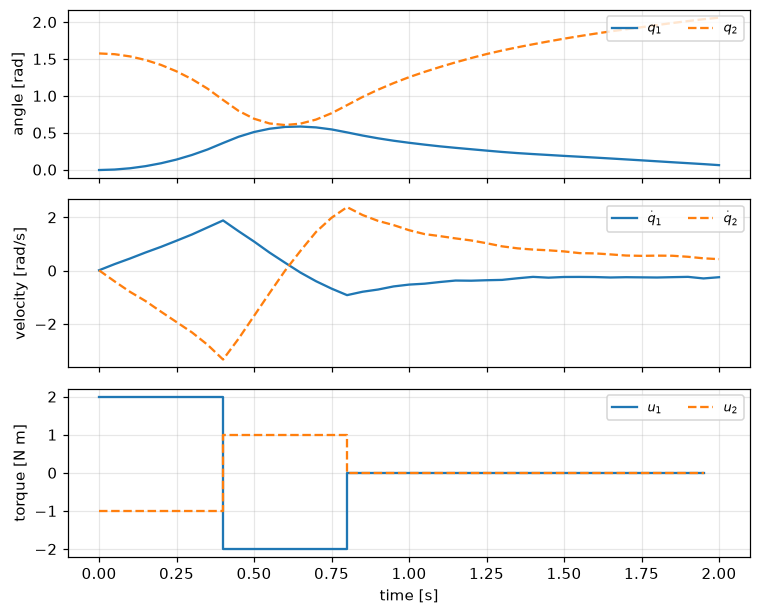

In [3]:
N = 40          # 2 s
A = 2.0         # torque amplitude [N m]

def pulse(A, N=N, n_on=16):
    # Accelerate for n_on/2 steps, brake for n_on/2 steps, then coast.
    us = np.zeros((N, 2))
    us[:n_on // 2] = [A, -A / 2]
    us[n_on // 2:n_on] = [-A, A / 2]
    return us

us = pulse(A)
xs, ys = env.rollout(us)
fig, axes = plot_timeseries(xs, us, config.dt)

The workspace view shows six snapshots of the arm (darker is later), the path of the end effector, and the noisy measurements $y_k$ of its position.

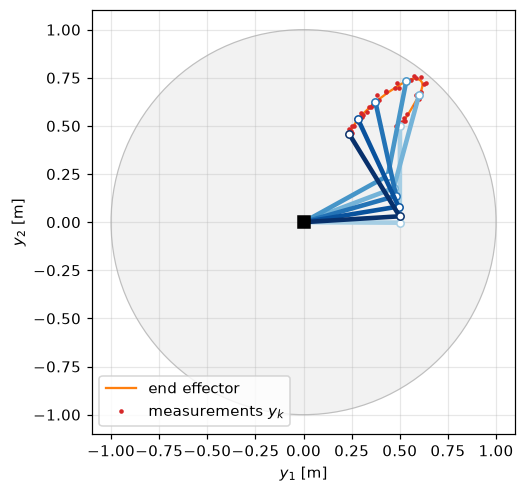

In [4]:
fig, ax = plt.subplots(figsize=(5, 5))
plot_workspace(ax, truth)
plot_snapshots(ax, xs, truth, n=6)
plot_ee_path(ax, xs, truth, color='C1', lw=1.5, label='end effector')
ax.plot(ys[:, 0], ys[:, 1], '.', color='C3', ms=4, label='measurements $y_k$')
ax.legend(loc='lower left');

In [5]:
HTML(animate_arm(xs, truth, config.dt, ys=ys).to_jshtml())

## 3. Prior predictive: parameter uncertainty spreads the trajectories

The controller cannot predict the arm exactly because it does not know $\theta$. The cell below rolls out the same pulse for 200 draws from the prior, without process noise, and compares a small and a large torque amplitude. `model.sample_params` returns a single `ArmParams` with batched fields, so one call to `transition` propagates all draws.

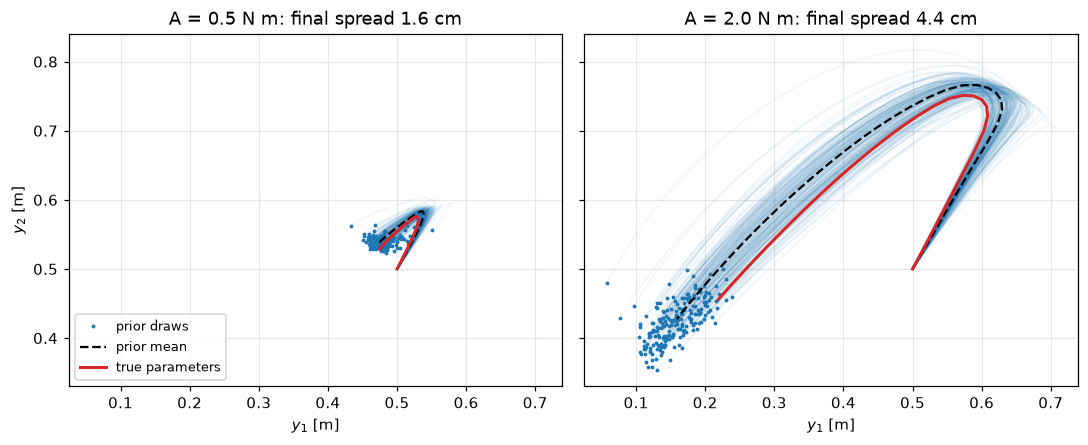

In [6]:
rng = np.random.default_rng(1)
draws = model.sample_params(rng, 200)

def predict(us, params, x0=np.asarray(config.x0_mean)):
    # Noise-free rollout x_{0:N}; params may be batched.
    xs = [x0]
    for u in us:
        xs.append(transition(xs[-1], u, params, config.dt, config.substeps))
    return np.stack(np.broadcast_arrays(*xs))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, amp in zip(axes, (0.5, 2.0)):
    u_amp = pulse(amp)
    ee = forward_kinematics(predict(u_amp, draws)[..., :2], draws)[1]
    ax.plot(ee[..., 0], ee[..., 1], color='C0', alpha=0.06, lw=1)
    ax.plot(ee[-1, :, 0], ee[-1, :, 1], '.', color='C0', ms=3, label='prior draws')
    plot_ee_path(ax, predict(u_amp, model.params), model.params, color='k', ls='--', lw=1.5, label='prior mean')
    plot_ee_path(ax, predict(u_amp, truth), truth, color='C3', lw=2, label='true parameters')
    spread = np.sqrt(np.trace(np.cov(ee[-1].T)))
    ax.set_title(f'A = {amp} N m: final spread {100 * spread:.1f} cm')
    ax.set_aspect('equal')
    ax.set_xlabel('$y_1$ [m]')
axes[0].set_ylabel('$y_2$ [m]')
axes[0].legend(loc='lower left', fontsize='small')
fig.tight_layout()

The larger torque spreads the predicted end-effector positions further, because $\theta$ scales how the arm responds to torque. A cautious controller avoids such inputs, because they make the outputs uncertain. A probing controller seeks them, because the measurements then discriminate between parameter values. This trade-off is the dual effect.

## 4. The dual effect: larger torques make the outputs more informative about $\theta$

The information constraint of the paper acts through $I_k = I[x_k; y_k \mid \mathbf{u}]$, which is bounded by $\tfrac12 \ln|I + R^{-1} C_k|$ with $C_k = \mathrm{Cov}[g(x_k)]$ under the open-loop prediction (Lemma 4.3 in the current draft of `main.tex`). The cell below computes $C_k$ over a horizon of $K = 20$ steps for the pulse family in two ways:

- **Monte Carlo** over $x_0$, $\theta$ and the process noise.
- **EKF prediction** of the augmented state $z = (x, \theta)$ with the model's Jacobians. Planners will use this moment recursion.

Setting the prior covariance of $\theta$ to zero gives the "$\theta$ known" curves, which isolate the information about the physical state.

In [7]:
K = 20
amplitudes = np.linspace(0, config.u_max, 9)
chol_Q = np.linalg.cholesky(model.Q)

def output_cov_mc(us, theta_known=False, n=4000, seed=2):
    rng = np.random.default_rng(seed)
    if theta_known:
        theta = np.broadcast_to(model.prior_mean, (n, model.n_theta))
    else:
        theta = model.sample_theta(rng, n)
    x = np.asarray(config.x0_mean) + np.asarray(config.x0_std) * rng.standard_normal((n, 4))
    C = []
    for u in us:
        x = model.f(x, u, theta) + rng.standard_normal((n, 4)) @ chol_Q.T
        C.append(np.cov(model.g(x, theta).T))
    return np.array(C)

def output_cov_ekf(us, theta_known=False):
    m, P, Q = model.z0_mean, model.z0_cov.copy(), model.Q_aug.copy()
    if theta_known:
        P[4:, 4:] = 0
        Q[4:, 4:] = 0
    C = []
    for u in us:
        F_z, _ = model.jacobian_f(m, u)
        m, P = model.f_aug(m, u), F_z @ P @ F_z.T + Q
        G = model.jacobian_g(m)
        C.append(G @ P @ G.T)
    return np.array(C)

def info_bound(C):
    # Per-step bound 1/2 ln|I + R^{-1} C_k|.
    return 0.5 * np.linalg.slogdet(np.eye(2) + np.linalg.solve(model.R, C))[1]

curves = {key: [] for key in ('mc', 'ekf', 'mc_known', 'ekf_known')}
for amp in amplitudes:
    u_amp = pulse(amp, N=K)
    curves['mc'].append(info_bound(output_cov_mc(u_amp)).sum())
    curves['ekf'].append(info_bound(output_cov_ekf(u_amp)).sum())
    curves['mc_known'].append(info_bound(output_cov_mc(u_amp, theta_known=True)).sum())
    curves['ekf_known'].append(info_bound(output_cov_ekf(u_amp, theta_known=True)).sum())
curves = {key: np.array(val) for key, val in curves.items()}

print(f"{'A [N m]':>8} {'MC':>7} {'EKF':>7} {'MC, θ known':>12} {'EKF, θ known':>13}   [nats over K = {K}]")
for i, amp in enumerate(amplitudes):
    print(f"{amp:8.2f} {curves['mc'][i]:7.2f} {curves['ekf'][i]:7.2f} "
          f"{curves['mc_known'][i]:12.2f} {curves['ekf_known'][i]:13.2f}")

 A [N m]      MC     EKF  MC, θ known  EKF, θ known   [nats over K = 20]
    0.00   20.63   20.67        20.53         20.67
    0.25   21.30   21.26        20.50         20.64
    0.50   22.88   22.72        20.40         20.54
    0.75   24.76   24.49        20.24         20.38
    1.00   26.51   26.17        20.04         20.17
    1.25   27.97   27.61        19.80         19.93
    1.50   29.11   28.73        19.55         19.67
    1.75   29.93   29.55        19.32         19.44
    2.00   30.50   30.09        19.14         19.26


Information about θ (EKF): 0.00 nats at A = 0, 10.83 nats at A = 2.0 N m
Largest relative gap between EKF and Monte Carlo: 1.4%


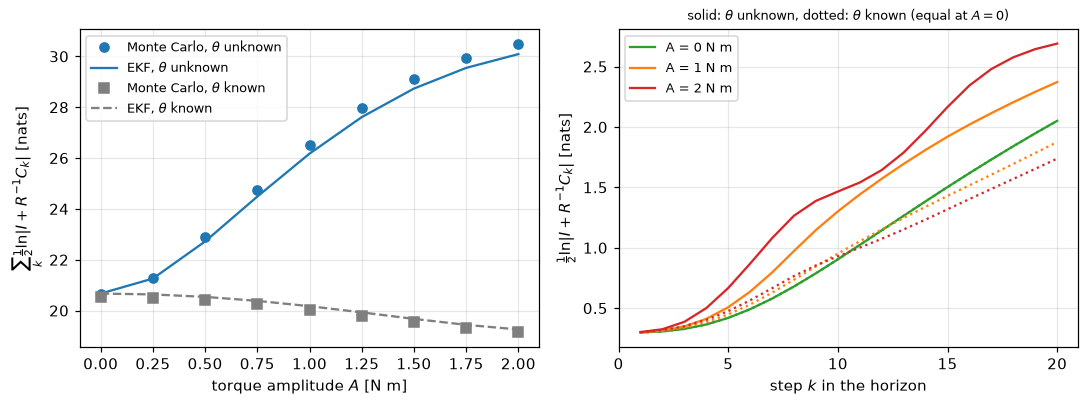

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
ax.plot(amplitudes, curves['mc'], 'o', color='C0', label=r'Monte Carlo, $\theta$ unknown')
ax.plot(amplitudes, curves['ekf'], '-', color='C0', label=r'EKF, $\theta$ unknown')
ax.plot(amplitudes, curves['mc_known'], 's', color='C7', label=r'Monte Carlo, $\theta$ known')
ax.plot(amplitudes, curves['ekf_known'], '--', color='C7', label=r'EKF, $\theta$ known')
ax.set_xlabel('torque amplitude $A$ [N m]')
ax.set_ylabel(r'$\sum_k \frac{1}{2}\ln|I + R^{-1}C_k|$ [nats]')
ax.legend(fontsize='small')

ax = axes[1]
steps = np.arange(1, K + 1)
for amp, color in zip((0.0, 1.0, 2.0), ('C2', 'C1', 'C3')):
    u_amp = pulse(amp, N=K)
    ax.plot(steps, info_bound(output_cov_ekf(u_amp)), '-', color=color, label=f'A = {amp:.0f} N m')
    ax.plot(steps, info_bound(output_cov_ekf(u_amp, theta_known=True)), ':', color=color)
ax.set_xticks(range(0, K + 1, 5))
ax.set_xlabel('step $k$ in the horizon')
ax.set_ylabel(r'$\frac{1}{2}\ln|I + R^{-1}C_k|$ [nats]')
ax.set_title(r'solid: $\theta$ unknown, dotted: $\theta$ known (equal at $A = 0$)', fontsize='small')
ax.legend(fontsize='small')
fig.tight_layout()

gain = curves['ekf'] - curves['ekf_known']
rel = np.abs(curves['ekf'] - curves['mc']) / curves['mc']
print(f"Information about θ (EKF): {gain[0]:.2f} nats at A = 0, {gain[-1]:.2f} nats at A = {amplitudes[-1]:.1f} N m")
print(f"Largest relative gap between EKF and Monte Carlo: {100 * rel.max():.1f}%")

The left panel shows that the bound grows with the torque amplitude when $\theta$ is unknown, and stays flat or decreases when $\theta$ is known. The growth therefore consists of information about $\theta$, and the controls decide how much of it the outputs carry. This is the incentive to probe that the information constraint adds to the cautious open-loop cost. The right panel shows that the parameter information accumulates over the horizon while the arm accelerates. The EKF prediction stays close to the Monte Carlo estimate, so an EKF-based planner can evaluate the information term with the model's Jacobians.

## 5. Playground

The sliders set the pulse and the true parameters of the plant, and *Run Interact* re-simulates the arm. The controller's prior is unaffected. The cell uses `interact_manual` because it draws only on request, which keeps headless execution (`jupyter nbconvert --execute`) from stalling on this kernel.

In [9]:
from ipywidgets import FloatSlider, IntSlider, interact_manual

@interact_manual(A=FloatSlider(value=2.0, min=0.0, max=config.u_max, step=0.1, continuous_update=False),
          n_on=IntSlider(value=16, min=2, max=N, step=2, continuous_update=False),
          m_p=FloatSlider(value=truth.m_p, min=0.0, max=1.5, step=0.05, continuous_update=False),
          damping=FloatSlider(value=truth.d1, min=0.0, max=0.6, step=0.05, continuous_update=False),
          seed=IntSlider(value=0, min=0, max=20, continuous_update=False))
def playground(A, n_on, m_p, damping, seed):
    params = replace(truth, m_p=m_p, d1=damping, d2=damping)
    us = pulse(A, n_on=n_on)
    xs, ys = RobotArm(params, config, seed=seed).rollout(us)
    fig, axd = plt.subplot_mosaic([['arm', 'q'], ['arm', 'dq'], ['arm', 'u']],
                                  figsize=(11, 4.6), layout='constrained')
    plot_workspace(axd['arm'], params)
    plot_snapshots(axd['arm'], xs, params, n=6)
    plot_ee_path(axd['arm'], xs, params, color='C1', lw=1.5)
    axd['arm'].plot(ys[:, 0], ys[:, 1], '.', color='C3', ms=4)
    plot_timeseries(xs, us, config.dt, axes=[axd['q'], axd['dq'], axd['u']])
    plt.show()

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='A', max=2.0), IntSlider(val…